# Keskar et al. (2017): Figure 3 — F1, C1, C2
**Independent PyTorch implementation based only on the attached paper.** Run top to bottom in Google Colab (Runtime → Change runtime type → GPU). No pretrained weights, external reproduction code, or hardcoded measurements are used.

## Source-grounded methodology
- **Paper §2.2, pp. 4–6:** Adam; SB batch 256; LB batch 10% of training set; 5 independent trials; train until objective stops improving; Figure 3 uses a randomly selected SB/LB pair; interpolate $\theta(\alpha)=(1-\alpha)\theta_{SB}+\alpha\theta_{LB}$ for $\alpha\in[-1,2]$. Plot *train/test* mean cross-entropy (left axis) and train/test accuracy (right axis); train solid, test dashed.
- **Appendix A, p. 12:** MNIST 60,000/10,000, CIFAR-10 50,000/10,000; no preprocessing specified.
- **Appendix B.1:** F1 = 784 → five BN/ReLU 512-unit layers → 10 logits.
- **Appendix B.3:** C1 = two Conv(64,5×5,stride 2) + MaxPool(3) stages → dense 384 → dense 192 → 10 outputs; BN/ReLU; dense dropout retention 0.5.
- **Appendix B.4:** C2 = convolution stacks [64×2,128×2,256×3,512×3,512×3], all 3×3 stride 1, max-pool(2) after each stack → dense 512 → 10 outputs; BN/ReLU and dropout following B.3. The appendix says “C3” in the C2 paragraph, apparently a typographical error given Table 1 and its last sentence.

**Implementation assumptions (not specified in paper):** input tensor scaling to [0,1] (no normalization/augmentation); BN epsilon/momentum defaults; BN applied before ReLU, including conv and hidden dense layers, but not output logits; C1 maxpool kernel=3, stride=2, padding=1 (paper gives only kernel); C1 convolution padding=2; C2 padding=1; dense dropout p=0.5 (C2 dense layer only); Adam lr=0.001 with PyTorch default betas/epsilon; epoch shuffling; stopping by patience on training cross-entropy. Models are evaluated in eval() mode with dropout disabled. For intermediate and extrapolated parameter values, BatchNorm running statistics are recalibrated using the full training dataset. At α = 0 and α = 1, the original trained models' BatchNorm statistics are preserved. This is an implementation assumption because the paper does not specify how to handle BatchNorm during interpolation.

**Computational reductions:** default QUICK mode uses 1 paired trial, a capped epoch budget, and fewer alpha points; all data are still used for endpoint training and full-dataset interpolation unless explicitly changed in CONFIG. FULL mode sets 5 trials, longer training and denser interpolation, but still cannot guarantee convergence identical to the authors'. C2 may require several hours on Colab GPU; FULL mode is substantially more expensive. **Do not interpret any plot before running cells: all plotted numbers are measured.**

In [19]:
import os, json, random, time, copy, csv
from pathlib import Path
import numpy as np, torch, torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

MODE = 'QUICK'  # 'QUICK' or 'FULL'
ARCHITECTURES = ['F1', 'C1', 'C2']
CONFIG = dict(trials=1, epochs=12, patience=5, alpha_points=31) if MODE=='QUICK' else dict(trials=5, epochs=100, patience=15, alpha_points=61)
SEED = 2027
DATA_ROOT = '/content/data' if os.path.isdir('/content') else './data'
OUTPUT = Path('/content/keskar_figure3' if os.path.isdir('/content') else './keskar_figure3')
OUTPUT.mkdir(parents=True,exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device', DEVICE, 'mode', MODE, 'configuration', CONFIG)
if DEVICE.type != 'cuda': print('WARNING: C2 on CPU will be very slow.')

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all(SEED)


device cuda mode QUICK configuration {'trials': 1, 'epochs': 12, 'patience': 5, 'alpha_points': 31}


In [5]:
# Input scaling to [0,1] is an explicit assumption; no augmentation or channel normalization.
transform = transforms.ToTensor()
mnist_train = datasets.MNIST(DATA_ROOT,train=True,download=True,transform=transform)
mnist_test  = datasets.MNIST(DATA_ROOT,train=False,download=True,transform=transform)
cifar_train = datasets.CIFAR10(DATA_ROOT,train=True,download=True,transform=transform)
cifar_test  = datasets.CIFAR10(DATA_ROOT,train=False,download=True,transform=transform)
DATASETS = {'F1':(mnist_train,mnist_test),'C1':(cifar_train,cifar_test),'C2':(cifar_train,cifar_test)}


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 492kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.2MB/s]
100%|██████████| 170M/170M [33:58<00:00, 83.7kB/s]


In [6]:
class F1(nn.Module):
    def __init__(self):
        super().__init__()
        layers=[]; d=784
        for _ in range(5):
            layers += [nn.Linear(d,512),nn.BatchNorm1d(512),nn.ReLU(inplace=True)]
            d=512
        layers += [nn.Linear(512,10)]
        self.net=nn.Sequential(*layers)
    def forward(self,x): return self.net(x.flatten(1))

class C1(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(3,64,5,stride=2,padding=2),nn.BatchNorm2d(64),nn.ReLU(True),nn.MaxPool2d(3,stride=2,padding=1),
            nn.Conv2d(64,64,5,stride=2,padding=2),nn.BatchNorm2d(64),nn.ReLU(True),nn.MaxPool2d(3,stride=2,padding=1))
        with torch.no_grad(): dim=self.features(torch.zeros(2,3,32,32)).flatten(1).shape[1]
        self.classifier=nn.Sequential(nn.Linear(dim,384),nn.BatchNorm1d(384),nn.ReLU(True),nn.Dropout(.5),
                                      nn.Linear(384,192),nn.BatchNorm1d(192),nn.ReLU(True),nn.Dropout(.5),nn.Linear(192,10))
    def forward(self,x): return self.classifier(self.features(x).flatten(1))

class C2(nn.Module):
    def __init__(self):
        super().__init__()
        layers=[]; incoming=3
        for count,channels in [(2,64),(2,128),(3,256),(3,512),(3,512)]:
            for _ in range(count):
                layers.extend([nn.Conv2d(incoming,channels,3,padding=1),nn.BatchNorm2d(channels),nn.ReLU(True)])
                incoming=channels
            layers.append(nn.MaxPool2d(2))
        self.features=nn.Sequential(*layers)
        self.classifier=nn.Sequential(nn.Linear(512,512),nn.BatchNorm1d(512),nn.ReLU(True),nn.Dropout(.5),nn.Linear(512,10))
    def forward(self,x): return self.classifier(self.features(x).flatten(1))

BUILD={'F1':F1,'C1':C1,'C2':C2}
for name in BUILD:
    m=BUILD[name](); print(name,'parameters',sum(p.numel() for p in m.parameters()))


F1 parameters 1462794
C1 parameters 283274
C2 parameters 14991946


In [7]:
def loader(ds, batch, shuffle=False):
    return DataLoader(ds,batch_size=batch,shuffle=shuffle,num_workers=2,pin_memory=(DEVICE.type=='cuda'),persistent_workers=True)

@torch.no_grad()
def evaluate(model,ds,batch_size=512):
    model.eval(); loss_sum=0.; correct=0; count=0
    for x,y in loader(ds,batch_size):
        x=x.to(DEVICE,non_blocking=True); y=y.to(DEVICE,non_blocking=True)
        logits=model(x); loss_sum+=F.cross_entropy(logits,y,reduction='sum').item()
        correct+=(logits.argmax(1)==y).sum().item(); count+=len(y)
    return {'loss':loss_sum/count,'accuracy':100*correct/count}

def train_one(name,regime,seed):
    seed_all(seed)
    ds,_=DATASETS[name]
    bs=256 if regime=='SB' else int(.1*len(ds))
    model=BUILD[name]().to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=.001)
    dl=loader(ds,bs,shuffle=True)
    best=float('inf'); bad=0; history=[]
    for epoch in range(1,CONFIG['epochs']+1):
        model.train(); running=0.; seen=0
        start=time.time()
        for x,y in dl:
            x=x.to(DEVICE,non_blocking=True); y=y.to(DEVICE,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            logits=model(x); loss=F.cross_entropy(logits,y)
            loss.backward(); opt.step()
            running+=loss.item()*len(y); seen+=len(y)
        # full train loss in eval mode; use this for stopping to match reported objective
        stats=evaluate(model,ds)
        history.append({'epoch':epoch,'batch':bs,'online_train_loss':running/seen,**stats})
        print(f'{name} {regime} epoch {epoch}/{CONFIG["epochs"]} trainCE={stats["loss"]:.4f} acc={stats["accuracy"]:.2f}% seconds={time.time()-start:.1f}',flush=True)
        if stats['loss'] < best-1e-4: best=stats['loss']; bad=0
        else: bad+=1
        if bad>=CONFIG['patience']:
            print('Early stop: no training-loss improvement'); break
    state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    del model, opt
    if DEVICE.type=='cuda': torch.cuda.empty_cache()
    return state,history


## Run the training experiments
Both SB and LB runs in each trial start with **identical parameters and initialization seed**; their data order differs because batch sizes differ. Save checkpoints immediately so training does not have to be repeated. Colab can disconnect during C2; completed checkpoints are reused.

In [17]:
runs={}
for name in ARCHITECTURES:
    runs[name]={}
    for trial in range(CONFIG['trials']):
        trial_seed=SEED+trial
        runs[name][trial]={}
        for regime in ['SB','LB']:
            path=OUTPUT/f'{name}_{regime}_trial{trial}.pt'
            if path.exists():
                item=torch.load(path,map_location='cpu',weights_only=False)
                print('Loaded',path)
            else:
                state,history=train_one(name,regime,trial_seed)
                item={'state':state,'history':history,'seed':trial_seed,'batch':256 if regime=='SB' else int(.1*len(DATASETS[name][0]))}
                torch.save(item,path)
                print('Saved',path)
            runs[name][trial][regime]=item


C2 SB epoch 1/12 trainCE=1.6031 acc=46.67% seconds=38.1
C2 SB epoch 2/12 trainCE=0.8560 acc=69.59% seconds=34.7
C2 SB epoch 3/12 trainCE=0.9943 acc=65.07% seconds=36.2
C2 SB epoch 4/12 trainCE=0.5327 acc=81.75% seconds=35.7
C2 SB epoch 5/12 trainCE=0.4368 acc=85.04% seconds=35.7
C2 SB epoch 6/12 trainCE=0.4772 acc=83.69% seconds=35.7
C2 SB epoch 7/12 trainCE=0.3362 acc=88.68% seconds=35.5
C2 SB epoch 8/12 trainCE=0.3451 acc=88.00% seconds=35.7
C2 SB epoch 9/12 trainCE=0.4065 acc=85.94% seconds=35.8
C2 SB epoch 10/12 trainCE=0.2697 acc=91.03% seconds=35.8
C2 SB epoch 11/12 trainCE=0.2538 acc=92.00% seconds=35.9
C2 SB epoch 12/12 trainCE=0.1664 acc=94.24% seconds=35.8
Saved /content/keskar_figure3/C2_SB_trial0.pt
C2 LB epoch 1/12 trainCE=2.5274 acc=10.00% seconds=37.4
C2 LB epoch 2/12 trainCE=2.2606 acc=12.87% seconds=36.7
C2 LB epoch 3/12 trainCE=2.5712 acc=14.73% seconds=36.8
C2 LB epoch 4/12 trainCE=2.7054 acc=17.07% seconds=36.9
C2 LB epoch 5/12 trainCE=1.8799 acc=32.86% seconds=36.9

## Parameter interpolation and evaluation
The paper selects one random pair from five trials; this QUICK reproduction uses trial 0. We evaluate all interpolation and extrapolation points on the full training and test datasets. Trainable parameters are linearly interpolated. BatchNorm running statistics are recalibrated at non-endpoint values using training data, while original endpoint statistics are preserved.

In [18]:
def interpolate_states(sb, lb, alpha):
    out = {}
    for k, a in sb.items():
        z = lb[k]
        if "running_var" in k or "running_mean" in k:
            out[k] = a.clone()
        elif torch.is_floating_point(a):
            out[k] = torch.lerp(a, z, float(alpha))
        else:
            out[k] = a.clone()
    return out

alphas=np.linspace(-1,2,CONFIG['alpha_points'])
# Guarantee exact endpoint sampling.
alphas=np.unique(np.concatenate([alphas,[0.,1.]]))
measurements={}
for name in ARCHITECTURES:
    sb=runs[name][0]['SB']['state']; lb=runs[name][0]['LB']['state']
    model=BUILD[name]().to(DEVICE)
    train_ds,test_ds=DATASETS[name]
    records=[]
    for i,a in enumerate(alphas):
        model.load_state_dict(interpolate_states(sb,lb,a))
        if a != 0 and a != 1:
            from torch.optim.swa_utils import update_bn
            update_bn(loader(DATASETS[name][0], 512), model, device=DEVICE)
        elif a == 0:
            model.load_state_dict(sb)
        elif a == 1:
            model.load_state_dict(lb)
        tr=evaluate(model,train_ds); te=evaluate(model,test_ds)
        rec={'architecture':name,'alpha':float(a),'train_loss':tr['loss'],'test_loss':te['loss'],
             'train_accuracy':tr['accuracy'],'test_accuracy':te['accuracy']}
        records.append(rec)
        print(f'{name} alpha={a:+.3f} trainCE={tr["loss"]:.4f} testCE={te["loss"]:.4f} trainAcc={tr["accuracy"]:.2f} testAcc={te["accuracy"]:.2f}',flush=True)
    measurements[name]=records
    with (OUTPUT/f'{name}_interpolation.csv').open('w',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=records[0].keys());writer.writeheader();writer.writerows(records)
    del model
    if DEVICE.type=='cuda':torch.cuda.empty_cache()


C2 alpha=-1.000 trainCE=0.4345 testCE=1.2751 trainAcc=90.44 testAcc=79.82
C2 alpha=-0.900 trainCE=0.3568 testCE=1.1602 trainAcc=91.57 testAcc=80.56
C2 alpha=-0.800 trainCE=0.2915 testCE=1.0565 trainAcc=92.65 testAcc=81.15
C2 alpha=-0.700 trainCE=0.2376 testCE=0.9627 trainAcc=93.59 testAcc=81.94
C2 alpha=-0.600 trainCE=0.1933 testCE=0.8778 trainAcc=94.36 testAcc=82.57
C2 alpha=-0.500 trainCE=0.1573 testCE=0.8012 trainAcc=95.13 testAcc=83.00
C2 alpha=-0.400 trainCE=0.1290 testCE=0.7326 trainAcc=95.82 testAcc=83.42
C2 alpha=-0.300 trainCE=0.1075 testCE=0.6730 trainAcc=96.44 testAcc=83.88
C2 alpha=-0.200 trainCE=0.0924 testCE=0.6230 trainAcc=96.82 testAcc=84.35
C2 alpha=-0.100 trainCE=0.0837 testCE=0.5831 trainAcc=97.17 testAcc=84.55
C2 alpha=+0.000 trainCE=0.1664 testCE=0.6869 trainAcc=94.24 testAcc=81.63
C2 alpha=+0.100 trainCE=0.0844 testCE=0.5317 trainAcc=97.26 testAcc=84.56
C2 alpha=+0.200 trainCE=0.0952 testCE=0.5197 trainAcc=97.06 testAcc=84.41
C2 alpha=+0.300 trainCE=0.1173 testCE=

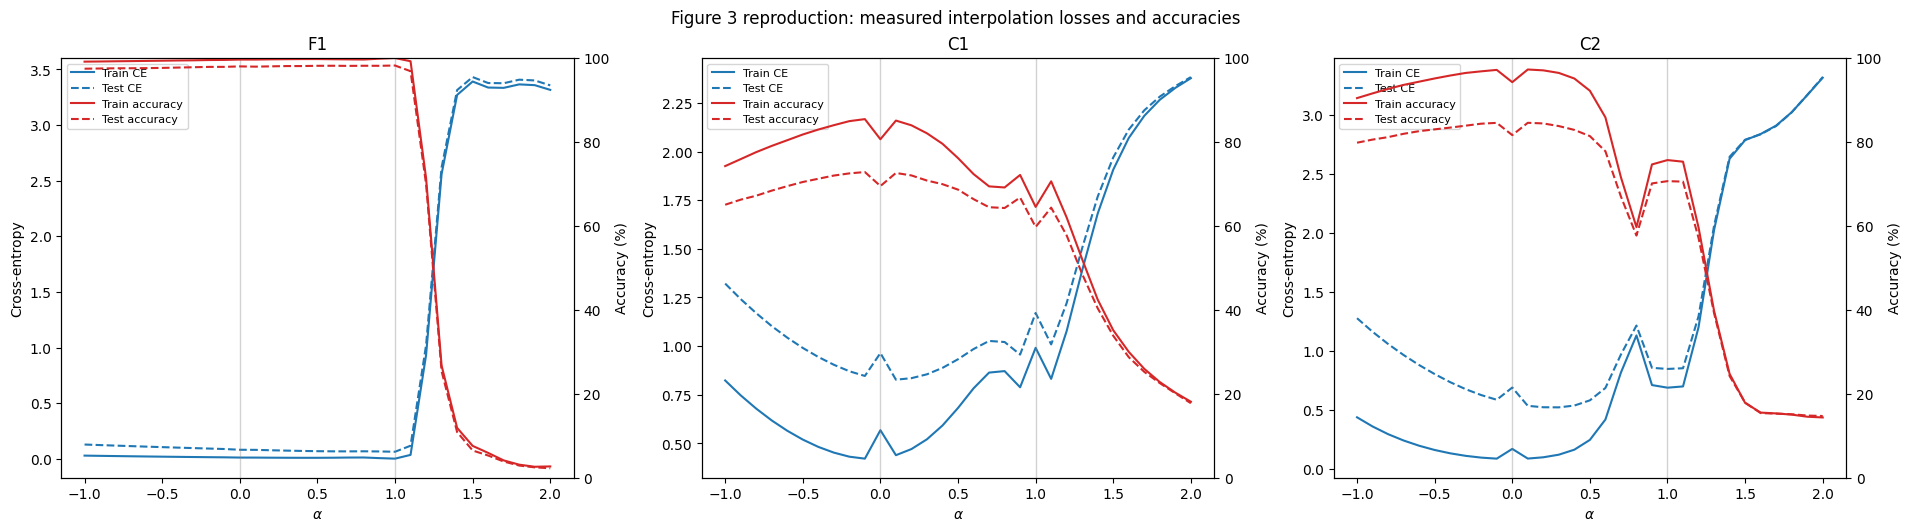

In [21]:
fig,axes=plt.subplots(1,3,figsize=(19,5.2),constrained_layout=True)
for ax,name in zip(axes,ARCHITECTURES):
    records=measurements[name]; x=[r['alpha'] for r in records]
    ax.plot(x,[r['train_loss'] for r in records],color='tab:blue',ls='-',label='Train CE')
    ax.plot(x,[r['test_loss'] for r in records],color='tab:blue',ls='--',label='Test CE')
    ax.set_xlabel(r'$\alpha$');ax.set_ylabel('Cross-entropy');ax.set_title(name)
    ax.axvline(0,color='gray',alpha=.35,lw=1);ax.axvline(1,color='gray',alpha=.35,lw=1)
    ax2=ax.twinx()
    ax2.plot(x,[r['train_accuracy'] for r in records],color='tab:red',ls='-',label='Train accuracy')
    ax2.plot(x,[r['test_accuracy'] for r in records],color='tab:red',ls='--',label='Test accuracy')
    ax2.set_ylim(0,100);ax2.set_ylabel('Accuracy (%)')
    lines=ax.get_lines()[:2]+ax2.get_lines()
    ax.legend(lines,[l.get_label() for l in lines],loc='best',fontsize=8)
fig.suptitle('Figure 3 reproduction: measured interpolation losses and accuracies')
fig.savefig(OUTPUT/'figure3_F1_C1_C2.png',dpi=200,bbox_inches='tight')
fig.savefig(OUTPUT/'figure3_F1_C1_C2.pdf',bbox_inches='tight')
plt.show()


In [ ]:
# Endpoint sanity checks and a compact reproducibility manifest.
summary={}
for name in ARCHITECTURES:
    rs=measurements[name]
    at0=min(rs,key=lambda r:abs(r['alpha']))
    at1=min(rs,key=lambda r:abs(r['alpha']-1))
    assert abs(at0['alpha'])<1e-10 and abs(at1['alpha']-1)<1e-10
    summary[name]={'SB':at0,'LB':at1}
    print(name,'SB:',at0,'LB:',at1)
manifest={'paper':'Keskar et al. (ICLR 2017), Figure 3 F1/C1/C2',
          'mode':MODE,'config':CONFIG,'seed':SEED,'device':str(DEVICE),
          'torch_version':torch.__version__,'assumptions':'See notebook methodology cell',
          'endpoints':summary}
(OUTPUT/'manifest.json').write_text(json.dumps(manifest,indent=2))
print('Saved all outputs to',OUTPUT)


## Saving from Colab
Results include per-regime model checkpoints (`.pt`), per-alpha measured metrics (`.csv`), figure (`.png` and `.pdf`), and a JSON manifest. Colab temporary storage can disappear when the runtime ends. Run the next cell to download a zip, or uncomment the Drive lines to copy results into Google Drive. Save the notebook itself using **File → Save a copy in Drive**.

### Limitations and interpretation
1. Default QUICK mode does not reproduce the paper's 5-run uncertainty estimates or convergence-to-plateau criterion. It is a *reduced experimental reproduction*, not a claim of numerical replication.
2. Paper leaves important implementation choices unspecified (padding, pool stride, initialization, exact optimizer hyperparameters, BN interpolation, precise stopping rule). These can materially change curve shape, especially C2.
3. Interpolating independently trained BN networks may create artifacts; results are a one-dimensional parameter-space diagnostic, not a direct measurement of Hessian sharpness.
4. The notebook uses full datasets for evaluations, so measured points are not hardcoded. If accuracy/loss are poor, increase epochs and inspect checkpoints rather than altering the plots.

In [ ]:
import shutil
archive=shutil.make_archive(str(OUTPUT),'zip',root_dir=str(OUTPUT))
print('Created:',archive)
if os.path.isdir('/content'):
    from google.colab import files
    files.download(archive)
# Optional persistent backup:
# from google.colab import drive
# drive.mount('/content/drive')
# shutil.copytree(OUTPUT,'/content/drive/MyDrive/keskar_figure3',dirs_exist_ok=True)
